# QLearning with Approximator

In [1]:
class Qlearner:
    def __init__(self, state_shape, num_action, epsilon=0.1, learning_rate=0.001, discount_factor=0.9):
        self.state_shape = state_shape # bordar vijegi state khas - vijegi haye yek state
        self.num_action = num_action
        self.learning_rate = learning_rate
        self.discount_factor = discount_factor
        self.epsilon = epsilon

        self.weight = np.zeros((self.num_action , self.state_shape)) # sotun = yek vijegi az state feli - satr = action haye momken

    def select_action(self, state):
        q_values = np.dot(self.weight , state) # estefade az zarb dakheli weight haye yek amal  dar bordar vijegi state feli
        if np.random.rand() < self.epsilon: #esploration
            action=np.random.randint(0, self.num_action)
        else:#exploitation
            action = np.argmax(q_values)
        return action

    def update(self, state, next_state, reward, action):
        cur_q_values = np.dot(self.weight , state)
        next_q_values = np.dot(self.weight , next_state)
        best_next_q_value = max(next_q_values)
        target = reward + self.discount_factor * best_next_q_value
        self.weight[action , :] += self.learning_rate * (target - cur_q_values[action]) * state


$error(w) = \frac{1}{2}(target - prediction)^2$

$w ⭠ w + \alpha (r + \gamma max_a Q(s' , a') - Q_w(s , a))state$

dar bala manzor az state haman bordar vijegi yek state ast

In [6]:
import gymnasium as gym
import numpy as np

n_episodes = 1000
total_reward =[]
env = gym.make('CartPole-v1')
agent = Qlearner(env.observation_space._shape[0] , env.action_space.n)

for i in range(n_episodes):
    state , info = env.reset()
    episode_rewards=[]
    while True: # gam haye yek episode
        action=agent.select_action(state)
        next_state, reward, terminated, truncated, info = env.step(action)
        episode_rewards.append(reward)
        agent.update(state, next_state, reward, action)
        state=next_state
        if terminated:
            break
    total_reward.append(np.sum(episode_rewards))

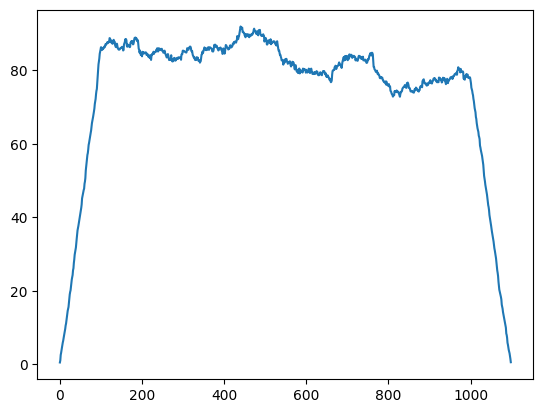

In [7]:
import matplotlib.pyplot as plt
plt.plot(np.convolve(total_reward, np.ones(100)/100))